# Домашнее задание 4. Классификация

Задание выполнил(а):

    Володина Надежда Николаевна
    

## Данные

В этой домашней работе мы будем обучать модели машинного обучения, проводить эксперименты, подбирать гиперпараметры, а также сравнивать и комбинировать различные алгоритмы. Задача заключается в решении задачи бинарной классификации — необходимо построить модель, которая по совокупности признаков определяет, превышает ли среднегодовой доход человека порог в $50 000.

Каждый объект выборки представляет собой информацию об одном человеке, для которого известны следующие признаки:

- age — возраст,

- workclass — тип занятости,

- fnlwgt — числовой коэффициент, отражающий, сколько человек в популяции представлено данным наблюдением (показатель, используемый в переписи населения, откуда и взят датасет),

- education — уровень образования,

- education-num — числовой эквивалент уровня образования,

- marital-status — семейное положение,

- occupation — род занятий,

- relationship — тип семейных связей,

- race — расовая принадлежность,

- sex — пол,

- capital-gain — прибыль от продажи активов,

- capital-loss — убыток от продажи активов,

- hours-per-week — количество рабочих часов в неделю.

Более подробное описание признаков можно найти в официальной документации датасета [Adult (Census Income)](http://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.names).

Целевой признак записан в переменной *>50K,<=50K*.

## Метрика качества

В задании мы будем оценивать качество моделей с помощью метрики AUC-ROC.

## Подбор гиперпараметров модели

В задачах машинного обучения следует различать параметры модели и гиперпараметры (структурные параметры). Обычно параметры модели настраиваются в ходе обучения (например, веса в линейной модели или структура решающего дерева), в то время как гиперпараметры задаются заранее (например, регуляризация в линейной модели или максимальная глубина решающего дерева). Каждая модель обычно имеет множество гиперпараметров, и нет универсальных наборов гиперпараметров, оптимально работающих во всех задачах, для каждой задачи нужно подбирать свой набор.

Для оптимизации гиперпараметров модели часто используют _перебор по сетке (grid search)_: для каждого гиперпараметра выбирается несколько значений, перебираются все комбинации значений и выбирается комбинация, на которой модель показывает лучшее качество (с точки зрения метрики, которая оптимизируется). Однако в этом случае нужно грамотно оценивать построенную модель, а именно делать разбиение на обучающую и тестовую выборку. Есть несколько схем, как это можно реализовать:

 - Разбить имеющуюся выборку на обучающую и тестовую. В этом случае сравнение большого числа моделей при переборе параметров приводит к ситуации, когда лучшая на тестовой подвыборке модель не сохраняет свои качества на новых данных. Можно сказать, что происходит _переобучение_ на тестовую выборку.
 - Для устранения описанной выше проблемы, можно разбить данные на 3 непересекающихся подвыборки: обучение (`train`), валидация (`validation`) и контроль (`test`). Валидационную подвыборку используют для сравнения моделей, а `test` — для окончательной оценки качества и сравнения семейств моделей с подобранными параметрами.
 - Другой способ сравнения моделей — кросс-валидация. Существуют различные схемы кросс-валидации:
    - Leave-One-Out
    - K-Fold
    - Многократное случайное разбиение выборки
  
Кросс-валидация вычислительно затратна, особенно если вы делаете перебор по сетке с очень большим числом комбинации. С учетом конечности времени на выполнение задания, возникает ряд компромиссов:
  - сетку можно делать более разреженной, перебирая меньше значений каждого параметра; однако, надо не забывать, что в таком случае можно пропустить хорошую комбинацию параметров;
  - кросс-валидацию можно делать с меньшим числом разбиений или фолдов, но в таком случае оценка качества кросс-валидации становится более шумной и увеличивается риск выбрать неоптимальный набор параметров из-за случайности разбиения;
  - параметры можно оптимизировать последовательно (жадно) — один за другим, а не перебирать все комбинации; такая стратегия не всегда приводит к оптимальному набору;
  - перебирать не все комбинации параметров, а небольшое число случайно выбранных.

### Задание 0. Загрузка данных

Загрузите датасет. Чтобы лучше понимать, с чем вы работаете/корректно ли вы загрузили данные можно вывести несколько первых строк на экран.

In [1]:
import pandas as pd
import numpy as np

In [2]:
# PATH = 'https://github.com/evgpat/ml_course_basic/raw/refs/heads/main/datasets/adult_census_income.csv'
PATH = 'https://raw.githubusercontent.com/evgpat/datasets/main/adult_income.csv'

In [3]:
data = pd.read_csv(PATH, sep=';')
data.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,">50K,<=50K"
0,34,Local-gov,284843,HS-grad,9,Never-married,Farming-fishing,Not-in-family,Black,Male,594,0,60,<=50K
1,40,Private,190290,Some-college,10,Divorced,Sales,Not-in-family,White,Male,0,0,40,<=50K
2,36,Local-gov,177858,Bachelors,13,Married-civ-spouse,Prof-specialty,Own-child,White,Male,0,0,40,<=50K
3,22,Private,184756,Some-college,10,Never-married,Sales,Own-child,White,Female,0,0,30,<=50K
4,47,Private,149700,Bachelors,13,Married-civ-spouse,Tech-support,Husband,White,Male,15024,0,40,>50K
5,18,Private,446771,Some-college,10,Never-married,Adm-clerical,Own-child,White,Male,0,0,25,<=50K
6,31,Federal-gov,108464,Assoc-acdm,12,Married-civ-spouse,Tech-support,Husband,White,Male,0,0,40,<=50K
7,18,?,423460,11th,7,Never-married,?,Own-child,White,Male,0,0,36,<=50K
8,25,Private,110138,HS-grad,9,Never-married,Other-service,Not-in-family,White,Male,0,0,40,<=50K
9,53,Federal-gov,167410,Bachelors,13,Divorced,Tech-support,Not-in-family,Amer-Indian-Eskimo,Male,0,0,40,<=50K


In [3]:
# запишем в файл csv, чтобы лежал локально на компьютере
import urllib.request

urllib.request.urlretrieve(PATH, "adult_income.csv")

('adult_income.csv', <http.client.HTTPMessage at 0x20f73599e50>)

Иногда в данных встречаются пропуски. Обычно в датасете на месте пропусков оказывается значение numpy.nan, если иное не указано в описании к данным. Более подробно о работе с пропусками в Pandas можно прочитать например [здесь](http://pandas.pydata.org/pandas-docs/stable/missing_data.html).

В данном датасете пропущенные значения обозначены знаком вопроса.

###**Задание 1. (0.5 баллов)**

####1.1. Найдите все признаки, имеющие пропущенные значения. Удалите из выборки все объекты с пропусками.

In [4]:
data.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
>50K,<=50K        0
dtype: int64

In [5]:
data.iloc[[7]]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,">50K,<=50K"
7,18,?,423460,11th,7,Never-married,?,Own-child,White,Male,0,0,36,<=50K


In [6]:
data = data.replace('?', None)

In [7]:
data.iloc[[7]]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,">50K,<=50K"
7,18,None,423460,11th,7,Never-married,None,Own-child,White,Male,0,0,36,<=50K


In [8]:
data.isnull().sum()

age                 0
workclass         929
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        933
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
>50K,<=50K          0
dtype: int64

In [9]:
data.shape

(16280, 14)

In [10]:
data = data.dropna()
data.shape

(15347, 14)

####1.2. Обычно после загрузки датасета всегда необходима его некоторая предобработка. В данном случае она будет заключаться в следующем:

 - Выделите целевую переменную в отдельную переменную, удалите ее из датасета и преобразуйте к бинарному формату.
 - Обратите внимание, что не все признаки являются вещественными. В начале мы будем работать только с вещественными признаками. Выделите их отдельно.

In [11]:
y = data['>50K,<=50K'].apply(lambda x: 0 if x == '<=50K' else 1)
X = data.drop('>50K,<=50K', axis=1)

In [12]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=42)

In [13]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15347 entries, 0 to 16279
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             15347 non-null  int64 
 1   workclass       15347 non-null  object
 2   fnlwgt          15347 non-null  int64 
 3   education       15347 non-null  object
 4   education-num   15347 non-null  int64 
 5   marital-status  15347 non-null  object
 6   occupation      15347 non-null  object
 7   relationship    15347 non-null  object
 8   race            15347 non-null  object
 9   sex             15347 non-null  object
 10  capital-gain    15347 non-null  int64 
 11  capital-loss    15347 non-null  int64 
 12  hours-per-week  15347 non-null  int64 
dtypes: int64(6), object(7)
memory usage: 1.6+ MB


In [14]:
# вещественные признаки
Xtrain_num = Xtrain.select_dtypes(exclude=['object'])
Xtest_num = Xtest.select_dtypes(exclude=['object'])

In [15]:
Xtrain_num.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
2764,34,29254,10,0,0,70
3556,73,29778,9,0,0,37
10941,44,219441,6,0,0,35
3572,19,63814,10,0,0,18
4591,36,168276,6,0,0,40


## Обучение классификаторов на вещественных признаках

В данном разделе необходимо будет работать только с вещественными признаками и целевой переменной.

В начале посмотрим как работает подбор параметров по сетке и как влияет на качество разбиение выборки. Сейчас и далее будем рассматривать 5 алгоритмов:
 - kNN
 - SGD Linear Classifier
 - Naive Bayes Classifier
 - Logistic Regression
 - SVC (Support Vector Classifier)

Для начала у первых двух алгоритмов выберем один гиперпараметр, который будем оптимизировать:
 - kNN — число соседей (*n_neighbors*)
 - SGD Linear Classifier — оптимизируемая функция (*loss*)

Остальные параметры оставляйте в значениях по умолчанию. Для подбора гиперпараметров воспользуйтесь перебором по сетке, который реализован в классе GridSearchCV. В качестве схемы кросс-валидации используйте 5-fold cv.

###**Задание 2. (1.5 балла)**

####2.1. Для каждого из первых двух алгоритмов подберите оптимальные значения указанных гиперпараметров. Постройте график среднего качества по кросс-валидации алгоритма при заданном значении гиперпараметра, на котором также отобразите доверительный интервал (доверительный интервал задается границами [mean - std, mean + std]).

In [16]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import roc_auc_score

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [18]:
# подбор гиперпараметров для kNN
knn = KNeighborsClassifier()
knn_params = {'n_neighbors': range(1, 51, 2)}

knn_grid = GridSearchCV(
    knn, 
    knn_params, 
    cv=cv, 
    scoring='roc_auc'
)
knn_grid.fit(Xtrain_num, ytrain)

knn_results = pd.DataFrame(knn_grid.cv_results_)
knn_mean_scores = knn_results['mean_test_score']
knn_std_scores = knn_results['std_test_score']
knn_params_values = knn_results['param_n_neighbors'].values

# Находим оптимальное значение
best_knn_idx = np.argmax(knn_mean_scores)
best_knn_n = knn_params_values[best_knn_idx]
best_knn_score = knn_mean_scores[best_knn_idx]

print(f"Оптимальное число соседей для kNN: {best_knn_n}")
print(f"Лучший AUC-ROC: {best_knn_score:.4f} (+/- {knn_std_scores[best_knn_idx]:.4f})")

Оптимальное число соседей для kNN: 5
Лучший AUC-ROC: 0.6302 (+/- 0.0131)


In [19]:
# подбор гиперпараметров для SGD Classifier
sgd = SGDClassifier()
sgd_params = {'loss': ['hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron']}

sgd_grid = GridSearchCV(
    sgd, 
    sgd_params, 
    cv=cv, 
    scoring='roc_auc',
    return_train_score=False,
    n_jobs=-1
)
sgd_grid.fit(Xtrain_num, ytrain)

sgd_results = pd.DataFrame(sgd_grid.cv_results_)

sgd_grouped = sgd_results.groupby('param_loss').agg({
    'mean_test_score': 'mean',
    'std_test_score': 'mean'
}).reset_index()

# Находим оптимальное значение
best_sgd_idx = np.argmax(sgd_grouped['mean_test_score'])
best_sgd_loss = sgd_grouped.iloc[best_sgd_idx]['param_loss']
best_sgd_score = sgd_grouped.iloc[best_sgd_idx]['mean_test_score']
best_sgd_std = sgd_grouped.iloc[best_sgd_idx]['std_test_score']

print(f"Оптимальная функция потерь для SGD: {best_sgd_loss}")
print(f"Лучший AUC-ROC: {best_sgd_score:.4f} (+/- {best_sgd_std:.4f})")

Оптимальная функция потерь для SGD: hinge
Лучший AUC-ROC: 0.6151 (+/- 0.0158)


In [20]:
import matplotlib.pyplot as plt

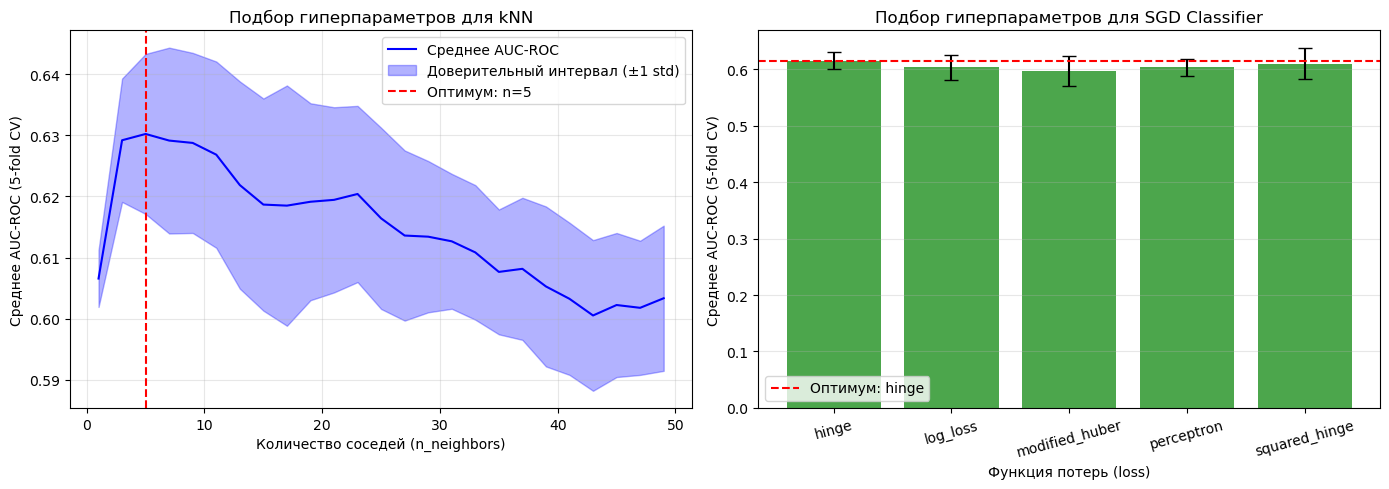

In [21]:
# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График для kNN
ax1.plot(knn_params_values, knn_mean_scores, 'b-', label='Среднее AUC-ROC')
ax1.fill_between(
    knn_params_values, 
    knn_mean_scores - knn_std_scores, 
    knn_mean_scores + knn_std_scores, 
    alpha=0.3, 
    color='b',
    label='Доверительный интервал (±1 std)'
)
ax1.axvline(x=best_knn_n, color='r', linestyle='--', label=f'Оптимум: n={best_knn_n}')
ax1.set_xlabel('Количество соседей (n_neighbors)')
ax1.set_ylabel('Среднее AUC-ROC (5-fold CV)')
ax1.set_title('Подбор гиперпараметров для kNN')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График для SGD
losses = sgd_grouped['param_loss'].values
mean_scores = sgd_grouped['mean_test_score'].values
std_scores = sgd_grouped['std_test_score'].values

x_positions = np.arange(len(losses))
ax2.bar(x_positions, mean_scores, yerr=std_scores, capsize=5, alpha=0.7, color='green')
ax2.set_xticks(x_positions)
ax2.set_xticklabels(losses, rotation=15)
ax2.set_ylabel('Среднее AUC-ROC (5-fold CV)')
ax2.set_xlabel('Функция потерь (loss)')
ax2.set_title('Подбор гиперпараметров для SGD Classifier')
ax2.axhline(y=best_sgd_score, color='r', linestyle='--', label=f'Оптимум: {best_sgd_loss}')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

####2.2. Что вы можете сказать о получившихся графиках?

**Ваш ответ здесь:**

По графику kNN метода видно, что с увеличением числа соседей - сначала резко растет значение метрики качества, а затем падает на отметке 0.63 и количестве соседей 5. Модель показала плохой результат на всех гиперпараметрах.

По графику SGD Classifier метода видно, что показатели метрик на всех гиперпараметрах одинаково низкие в диапазоне от 0.6 до 0.62 и достаточно большими доверительными интервалами, что говорит о большом разбросе, кроме hinge. Модель показала плохой результат на всех гиперпараметрах.

###**Задание 3. (1.5 балла)**

####3.1. Подберите параметр регуляризации C в алгоритмах LogisticRegression и SVC.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [23]:
# Значения C для перебора
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

In [24]:
# подбор гиперпараметров для Logistic Regression
logreg = LogisticRegression()
logreg_params = {'C': C_values}

logreg_grid = GridSearchCV(
    logreg, 
    logreg_params, 
    cv=cv, 
    scoring='roc_auc', 
    n_jobs=-1)
logreg_grid.fit(Xtrain_num, ytrain)

logreg_results = pd.DataFrame(logreg_grid.cv_results_)
best_logreg_C = logreg_results.loc[logreg_results['mean_test_score'].idxmax(), 'param_C']
best_logreg_score = logreg_results['mean_test_score'].max()

print("Logistic Regression:\n")
print(f"Оптимальный C: {best_logreg_C}")
print(f"Лучший AUC-ROC: {best_logreg_score:.4f}")

Logistic Regression:

Оптимальный C: 0.001
Лучший AUC-ROC: 0.5843


C:\Users\User\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Пробовала взять значение max_iter по умолчанию 100. Алгоритм не сошелся за 100 итераций и выдал ошибку ConvergenceWarning. Поэтому переделала на значение 1000 и включила его в анализ как доп вариант.

In [25]:
# подбор гиперпараметров для Logistic Regression (with max_iter)
logreg_with_max_iter = LogisticRegression(max_iter=1000)
logreg_params = {'C': C_values}

logreg_grid_with_max_iter = GridSearchCV(
    logreg_with_max_iter, 
    logreg_params, 
    cv=cv, 
    scoring='roc_auc', 
    n_jobs=-1)
logreg_grid_with_max_iter.fit(Xtrain_num, ytrain)

logreg_results_with_max_iter = pd.DataFrame(logreg_grid_with_max_iter.cv_results_)
best_logreg_C_with_max_iter = logreg_results_with_max_iter.loc[logreg_results_with_max_iter['mean_test_score'].idxmax(), 'param_C']
best_logreg_score_with_max_iter = logreg_results_with_max_iter['mean_test_score'].max()

print("Logistic Regression (with max_iter):\n")
print(f"Оптимальный C: {best_logreg_C_with_max_iter}")
print(f"Лучший AUC-ROC: {best_logreg_score_with_max_iter:.4f}")

Logistic Regression (with max_iter):

Оптимальный C: 0.001
Лучший AUC-ROC: 0.8271


In [26]:
# подбор гиперпараметров для SVC
svc = SVC()
svc_params = {'C': C_values}
svc_grid = GridSearchCV(svc, svc_params, cv=cv, scoring='roc_auc', n_jobs=-1)
svc_grid.fit(Xtrain_num, ytrain)

svc_results = pd.DataFrame(svc_grid.cv_results_)
best_svc_C = svc_results.loc[svc_results['mean_test_score'].idxmax(), 'param_C']
best_svc_score = svc_results['mean_test_score'].max()

print("SVC\n")
print(f"Оптимальный C: {best_svc_C}")
print(f"Лучший AUC-ROC: {best_svc_score:.4f}")

SVC

Оптимальный C: 100.0
Лучший AUC-ROC: 0.6828


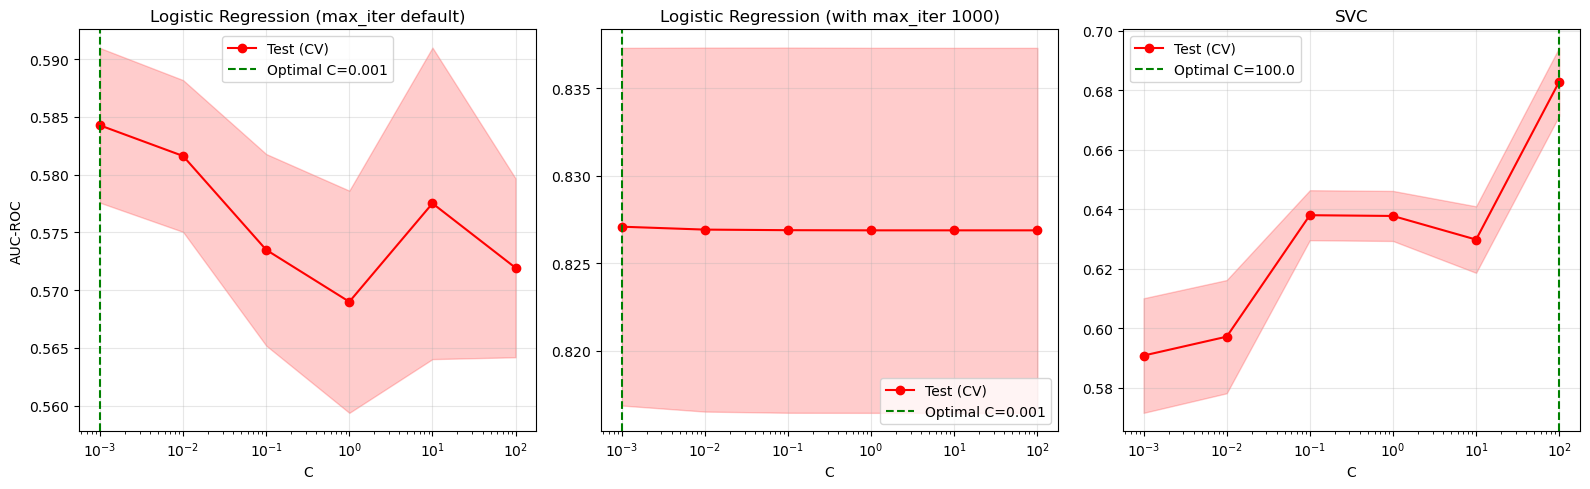

In [27]:
# визуализация
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# Logistic Regression (max_iter default)
ax1.plot(C_values, logreg_results['mean_test_score'], 'r-o', label='Test (CV)')
ax1.fill_between(C_values, 
                 logreg_results['mean_test_score'] - logreg_results['std_test_score'],
                 logreg_results['mean_test_score'] + logreg_results['std_test_score'],
                 alpha=0.2, color='r')
ax1.axvline(best_logreg_C, color='g', linestyle='--', label=f'Optimal C={best_logreg_C}')
ax1.set_xscale('log')
ax1.set_xlabel('C')
ax1.set_ylabel('AUC-ROC')
ax1.set_title('Logistic Regression (max_iter default)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Logistic Regression  (with max_iter 1000)
ax2.plot(C_values, logreg_results_with_max_iter['mean_test_score'], 'r-o', label='Test (CV)')
ax2.fill_between(C_values, 
                 logreg_results_with_max_iter['mean_test_score'] - logreg_results_with_max_iter['std_test_score'],
                 logreg_results_with_max_iter['mean_test_score'] + logreg_results_with_max_iter['std_test_score'],
                 alpha=0.2, color='r')
ax2.axvline(best_logreg_C_with_max_iter, color='g', linestyle='--', label=f'Optimal C={best_logreg_C_with_max_iter}')
ax2.set_xscale('log')
ax2.set_xlabel('C')
ax2.set_title('Logistic Regression (with max_iter 1000)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# SVC
ax3.plot(C_values, svc_results['mean_test_score'], 'r-o', label='Test (CV)')
ax3.fill_between(C_values,
                 svc_results['mean_test_score'] - svc_results['std_test_score'],
                 svc_results['mean_test_score'] + svc_results['std_test_score'],
                 alpha=0.2, color='r')
ax3.axvline(best_svc_C, color='g', linestyle='--', label=f'Optimal C={best_svc_C}')
ax3.set_xscale('log')
ax3.set_xlabel('C')
ax3.set_title('SVC')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

###**Задание 4. (1 балл)**

####4.1. Изучите документацию по алгоритму [Naive Bayes Classifier](https://scikit-learn.org/stable/modules/naive_bayes.html) и подберите возможные гиперпараметры для этого алгоритма.

In [28]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB

In [29]:
# для GaussianNB
gnb = GaussianNB()
params_gnb = {'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}

# GridSearchCV с 5-fold CV
grid_gnb = GridSearchCV(gnb, params_gnb, cv=5, scoring='roc_auc')
grid_gnb.fit(Xtrain_num, ytrain)
print('GaussianNB')
print(f"Оптимальные параметры: {grid_gnb.best_params_}")
print(f"Лучший AUC-ROC: {grid_gnb.best_score_:.4f}")

# Для MultinomialNB
mnb = MultinomialNB()
params_mnb = {
    'alpha': [0.0, 0.1, 0.5, 1.0, 2.0],
    'fit_prior': [True, False]
}
# GridSearchCV с 5-fold CV
grid_mnb = GridSearchCV(mnb, params_mnb, cv=5, scoring='roc_auc')
grid_mnb.fit(Xtrain_num, ytrain)
print('\nMultinomialNB:')
print(f"Оптимальные параметры: {grid_mnb.best_params_}")
print(f"Лучший AUC-ROC: {grid_mnb.best_score_:.4f}")

# Для ComplementNB
cnb = ComplementNB()
params_cnb = {
    'alpha': [0.0, 0.1, 0.5, 1.0, 2.0],
    'fit_prior': [True, False]
}
# GridSearchCV с 5-fold CV
grid_cnb = GridSearchCV(cnb, params_cnb, cv=5, scoring='roc_auc')
grid_cnb.fit(Xtrain_num, ytrain)
print('\nComplementNB')
print(f"Оптимальные параметры: {grid_cnb.best_params_}")
print(f"Лучший AUC-ROC: {grid_cnb.best_score_:.4f}")

GaussianNB
Оптимальные параметры: {'var_smoothing': 1e-09}
Лучший AUC-ROC: 0.8159

MultinomialNB:
Оптимальные параметры: {'alpha': 0.0, 'fit_prior': True}
Лучший AUC-ROC: 0.5984

ComplementNB
Оптимальные параметры: {'alpha': 0.0, 'fit_prior': True}
Лучший AUC-ROC: 0.5983


###**Задание 5. (0.5 балла)**

При обучении алгоритмов стоит обращать внимание не только на качество, но и каким образом они работают с данными. В этой задаче получилось так, что некоторые из используемых алгоритмов чувствительны к масштабу признаков. Чтобы убедиться, что это как-то могло повлиять на качество давайте посмотрим на сами признаки.

####5.1. Постройте гистограммы для признаков *age*, *fnlwgt*, *capital-gain*. 

In [30]:
Xtrain_num.head(4)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
2764,34,29254,10,0,0,70
3556,73,29778,9,0,0,37
10941,44,219441,6,0,0,35
3572,19,63814,10,0,0,18


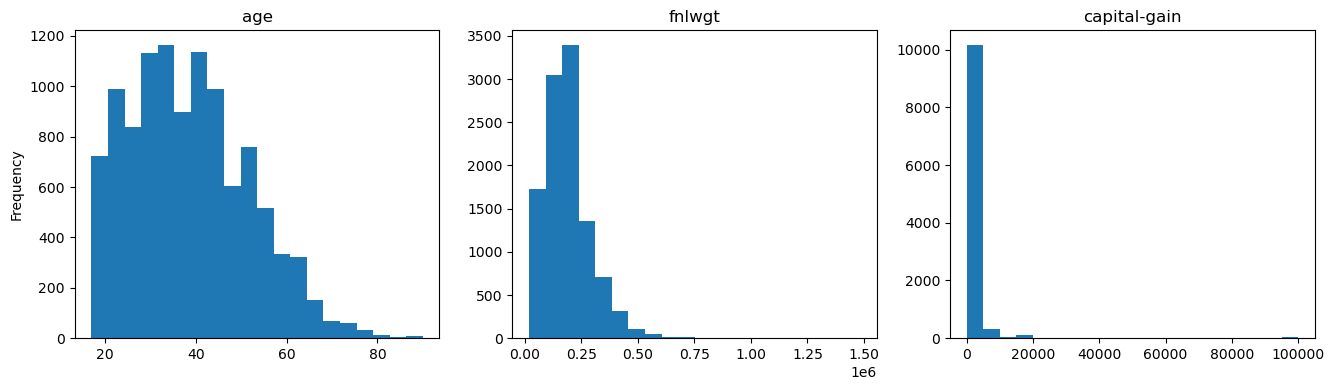

In [31]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

ax1.hist(Xtrain_num['age'], bins=20)
ax1.set_title('age')
ax1.set_ylabel('Frequency')

ax2.hist(Xtrain_num['fnlwgt'], bins=20)
ax2.set_title('fnlwgt')

ax3.hist(Xtrain_num['capital-gain'], bins=20)
ax3.set_title('capital-gain')

plt.show()

####5.2. Исходя из получившихся графиков напишите:
- в чем заключается особенность данных
- на какие алгоритмы это может повлиять
- может ли масшитабирование повлиять на работу этих алгоритмов?

In [32]:
Xtrain_num['fnlwgt'].max()
Xtrain_num['fnlwgt'].min()
Xtrain_num['age'].min()
Xtrain_num['age'].max()
Xtrain_num['capital-gain'].min()
Xtrain_num['capital-gain'].max()

99999

**Ваш ответ здесь:**

1. Особенность этих данных заключается в сильно разном диапазоне значений. У age - от 17 до 90, у fnlwgt - диапазон от 19302 до 1484705, у capital-gain - от 0 до 99999. Т.е. слишком разный масштаб.
2. Это может повлиять на все алгоритмы, чувствительные к масштабу. В нашем случае это kNN, SGD, Logistic Regression, SVC, Naive Bayes.
3. Да, масштабирование может повлиять на работу этих алгоритмов: улучшить качество модели. Без стандартизации признаки с большими значениями (например, fnlwgt, capital-gain) будут доминировать, поэтому качество модели может быть низким, что и показали наши модели на практике.

**Задание 6. (1 балл)**

Масштабирование признаков можно выполнить, например, одним из следующих способов способами:
 - $x_{new} = \dfrac{x - \mu}{\sigma}$, где $\mu, \sigma$ — среднее и стандартное отклонение значения признака по всей выборке (см. функцию [scale](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.scale.html))
 - $x_{new} = \dfrac{x - x_{min}}{x_{max} - x_{min}}$, где $[x_{min}, x_{max}]$ — минимальный интервал значений признака

Похожие схемы масштабирования приведены в классах [StandardScaler](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler) и [MinMaxScaler](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html#sklearn.preprocessing.MinMaxScaler).

####6.1. Масштабируйте все вещественные признаки одним из указанных способов и подберите оптимальные значения гиперпараметров аналогично пункту выше.

In [33]:
from sklearn.preprocessing import StandardScaler

In [35]:
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(Xtrain_num)
X_test_num_scaled = scaler.transform(Xtest_num)

In [36]:
# подбор гиперпараметров для kNN (с нормализацией)
knn2 = KNeighborsClassifier()
knn2_params = {'n_neighbors': range(1, 51, 2)}

knn2_grid = GridSearchCV(
    knn2, 
    knn2_params, 
    cv=cv, 
    scoring='roc_auc'
    )
knn2_grid.fit(X_train_num_scaled, ytrain)

knn2_results = pd.DataFrame(knn2_grid.cv_results_)
knn2_mean_scores = knn2_results['mean_test_score']
knn2_std_scores = knn2_results['std_test_score']
knn2_params_values = knn2_results['param_n_neighbors'].values

# Находим оптимальное значение
best_knn2_idx = np.argmax(knn2_mean_scores)
best_knn2_n = knn2_params_values[best_knn2_idx]
best_knn2_score = knn2_mean_scores[best_knn2_idx]

print(f"Оптимальное число соседей для kNN: {best_knn2_n}")
print(f"Среднее качество AUC-ROC: {best_knn2_score:.4f} (+/- {knn2_std_scores[best_knn2_idx]:.4f})")

Оптимальное число соседей для kNN: 39
Среднее качество AUC-ROC: 0.8354 (+/- 0.0096)


In [37]:
# подбор гиперпараметров для SGD Classifier (с нормализацией)
sgd2 = SGDClassifier()
sgd2_params = {'loss': ['hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron']}

sgd2_grid = GridSearchCV(
    sgd2, 
    sgd2_params, 
    cv=cv, 
    scoring='roc_auc'
)
sgd2_grid.fit(X_train_num_scaled, ytrain)

sgd2_results = pd.DataFrame(sgd2_grid.cv_results_)

sgd2_grouped = sgd2_results.groupby('param_loss').agg({
    'mean_test_score': 'mean',
    'std_test_score': 'mean'
}).reset_index()

# Находим оптимальное значение
best_sgd2_idx = np.argmax(sgd2_grouped['mean_test_score'])
best_sgd2_loss = sgd2_grouped.iloc[best_sgd2_idx]['param_loss']
best_sgd2_score = sgd2_grouped.iloc[best_sgd2_idx]['mean_test_score']
best_sgd2_std = sgd2_grouped.iloc[best_sgd2_idx]['std_test_score']

print(f"Оптимальная функция потерь для SGD: {best_sgd2_loss}")
print(f"Среднее качество AUC-ROC: {best_sgd2_score:.4f} (+/- {best_sgd2_std:.4f})")

Оптимальная функция потерь для SGD: log_loss
Среднее качество AUC-ROC: 0.8199 (+/- 0.0090)


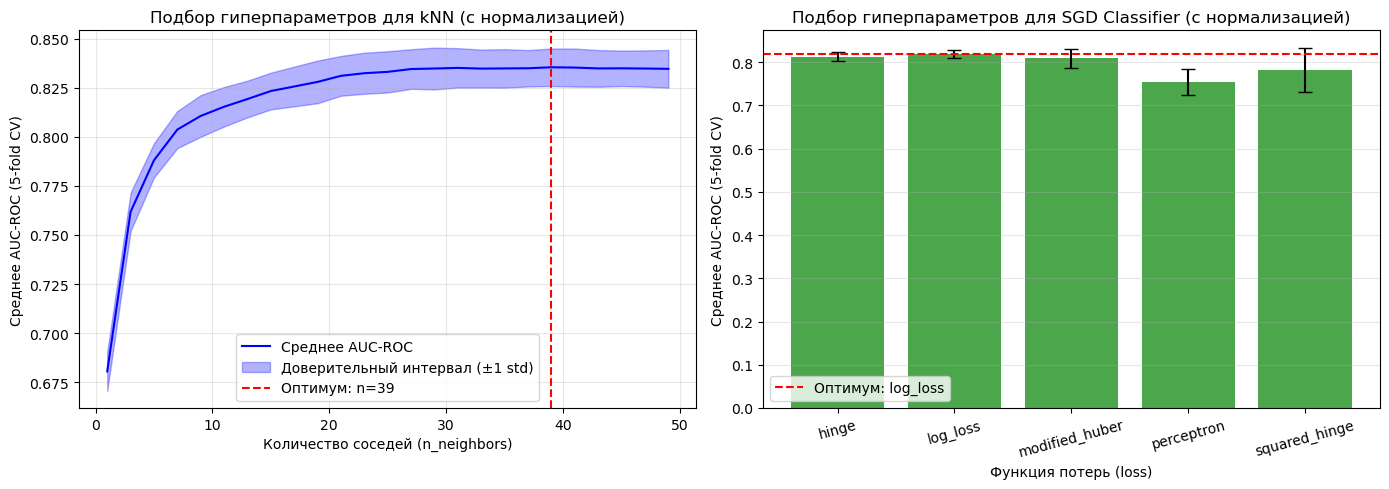

In [38]:
# Построение графиков kNN и SGD (с нормализацией)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График для kNN
ax1.plot(knn2_params_values, knn2_mean_scores, 'b-', label='Среднее AUC-ROC')
ax1.fill_between(
    knn2_params_values, 
    knn2_mean_scores - knn2_std_scores, 
    knn2_mean_scores + knn2_std_scores, 
    alpha=0.3, 
    color='b',
    label='Доверительный интервал (±1 std)'
)
ax1.axvline(x=best_knn2_n, color='r', linestyle='--', label=f'Оптимум: n={best_knn2_n}')
ax1.set_xlabel('Количество соседей (n_neighbors)')
ax1.set_ylabel('Среднее AUC-ROC (5-fold CV)')
ax1.set_title('Подбор гиперпараметров для kNN (с нормализацией)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# График для SGD
losses2 = sgd2_grouped['param_loss'].values
mean2_scores = sgd2_grouped['mean_test_score'].values
std2_scores = sgd2_grouped['std_test_score'].values

x2_positions = np.arange(len(losses2))
ax2.bar(x2_positions, mean2_scores, yerr=std2_scores, capsize=5, alpha=0.7, color='green')
ax2.set_xticks(x2_positions)
ax2.set_xticklabels(losses2, rotation=15)
ax2.set_ylabel('Среднее AUC-ROC (5-fold CV)')
ax2.set_xlabel('Функция потерь (loss)')
ax2.set_title('Подбор гиперпараметров для SGD Classifier (с нормализацией)')
ax2.axhline(y=best_sgd2_score, color='r', linestyle='--', label=f'Оптимум: {best_sgd2_loss}')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [39]:
# подбор гиперпараметров для Logistic Regression (с нормализацией)
logreg2 = LogisticRegression()
logreg2_params = {'C': C_values}

logreg2_grid = GridSearchCV(
    logreg2, 
    logreg2_params, 
    cv=cv, 
    scoring='roc_auc'
)
logreg2_grid.fit(X_train_num_scaled, ytrain)

logreg2_results = pd.DataFrame(logreg2_grid.cv_results_)
best_logreg2_C = logreg2_results.loc[logreg2_results['mean_test_score'].idxmax(), 'param_C']
best_logreg2_score = logreg2_results['mean_test_score'].max()

print("Logistic Regression (с нормализацией):\n")
print(f"Оптимальный C: {best_logreg2_C}")
print(f"Лучший AUC-ROC: {best_logreg2_score:.4f}")

Logistic Regression (с нормализацией):

Оптимальный C: 0.1
Лучший AUC-ROC: 0.8271


In [40]:
# подбор гиперпараметров для Logistic Regression  (с нормализацией и with max_iter)
logreg2_with_max_iter = LogisticRegression(max_iter=1000)
logreg2_params = {'C': C_values}

logreg2_grid_with_max_iter = GridSearchCV(
    logreg2_with_max_iter, 
    logreg2_params, 
    cv=cv, 
    scoring='roc_auc'
)
logreg2_grid_with_max_iter.fit(X_train_num_scaled, ytrain)

logreg2_results_with_max_iter = pd.DataFrame(logreg2_grid_with_max_iter.cv_results_)
best_logreg2_C_with_max_iter = logreg2_results_with_max_iter.loc[logreg2_results_with_max_iter['mean_test_score'].idxmax(), 'param_C']
best_logreg2_score_with_max_iter = logreg2_results_with_max_iter['mean_test_score'].max()

print("Logistic Regression (с нормализацией и with max_iter):\n")
print(f"Оптимальный C: {best_logreg2_C_with_max_iter}")
print(f"Лучший AUC-ROC: {best_logreg2_score_with_max_iter:.4f}")

Logistic Regression (с нормализацией и with max_iter):

Оптимальный C: 0.1
Лучший AUC-ROC: 0.8271


In [41]:
# подбор гиперпараметров для SVC (с нормализацией)
svc2 = SVC()
svc2_params = {'C': C_values}
svc2_grid = GridSearchCV(svc2, svc2_params, cv=cv, scoring='roc_auc')
svc2_grid.fit(X_train_num_scaled, ytrain)

svc2_results = pd.DataFrame(svc2_grid.cv_results_)
best_svc2_C = svc2_results.loc[svc2_results['mean_test_score'].idxmax(), 'param_C']
best_svc2_score = svc2_results['mean_test_score'].max()

print("SVC (с нормализацией)\n")
print(f"Оптимальный C: {best_svc2_C}")
print(f"Лучший AUC-ROC: {best_svc2_score:.4f}")

SVC (с нормализацией)

Оптимальный C: 0.001
Лучший AUC-ROC: 0.8187


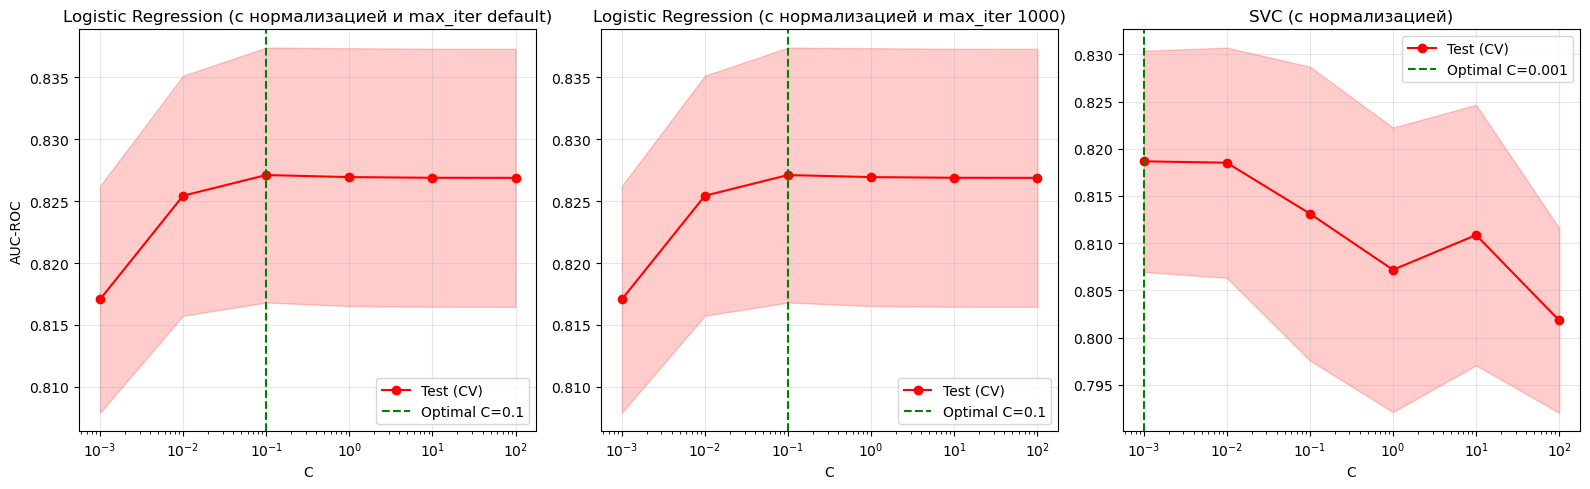

In [42]:
# визуализация Logistic Regression и SVC (с нормализацией)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# Logistic Regression (max_iter default)
ax1.plot(C_values, logreg2_results['mean_test_score'], 'r-o', label='Test (CV)')
ax1.fill_between(C_values, 
                 logreg2_results['mean_test_score'] - logreg2_results['std_test_score'],
                 logreg2_results['mean_test_score'] + logreg2_results['std_test_score'],
                 alpha=0.2, color='r')
ax1.axvline(best_logreg2_C, color='g', linestyle='--', label=f'Optimal C={best_logreg2_C}')
ax1.set_xscale('log')
ax1.set_xlabel('C')
ax1.set_ylabel('AUC-ROC')
ax1.set_title('Logistic Regression (с нормализацией и max_iter default)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Logistic Regression  (with max_iter 1000)
ax2.plot(C_values, logreg2_results_with_max_iter['mean_test_score'], 'r-o', label='Test (CV)')
ax2.fill_between(C_values, 
                 logreg2_results_with_max_iter['mean_test_score'] - logreg2_results_with_max_iter['std_test_score'],
                 logreg2_results_with_max_iter['mean_test_score'] + logreg2_results_with_max_iter['std_test_score'],
                 alpha=0.2, color='r')
ax2.axvline(best_logreg2_C_with_max_iter, color='g', linestyle='--', label=f'Optimal C={best_logreg2_C_with_max_iter}')
ax2.set_xscale('log')
ax2.set_xlabel('C')
ax2.set_title('Logistic Regression (с нормализацией и max_iter 1000)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# SVC
ax3.plot(C_values, svc2_results['mean_test_score'], 'r-o', label='Test (CV)')
ax3.fill_between(C_values,
                 svc2_results['mean_test_score'] - svc2_results['std_test_score'],
                 svc2_results['mean_test_score'] + svc2_results['std_test_score'],
                 alpha=0.2, color='r')
ax3.axvline(best_svc2_C, color='g', linestyle='--', label=f'Optimal C={best_svc2_C}')
ax3.set_xscale('log')
ax3.set_xlabel('C')
ax3.set_title('SVC (с нормализацией)')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
from sklearn.preprocessing import MinMaxScaler

scaler2 = MinMaxScaler()
X_train_num_scaled_minmax = scaler2.fit_transform(Xtrain_num)
X_test_num_scaled_minmax = scaler2.transform(Xtest_num)

In [44]:
# для GaussianNB (с нормализацией StandartScaler)
gnb2 = GaussianNB()
params_gnb2 = {'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}

# GridSearchCV с 5-fold CV
grid_gnb2 = GridSearchCV(gnb2, params_gnb2, cv=5, scoring='roc_auc')
grid_gnb2.fit(X_train_num_scaled, ytrain)
print('GaussianNB (с нормализацией):')
print(f"Оптимальные параметры: {grid_gnb2.best_params_}")
print(f"Лучший AUC-ROC: {grid_gnb2.best_score_:.4f}")

# Для MultinomialNB (с нормализацией MinMaxScaler)
mnb2 = MultinomialNB()
params_mnb2 = {
    'alpha': [0.0, 0.1, 0.5, 1.0, 2.0],
    'fit_prior': [True, False]
}
# GridSearchCV с 5-fold CV
grid_mnb2 = GridSearchCV(mnb2, params_mnb2, cv=5, scoring='roc_auc')
grid_mnb2.fit(X_train_num_scaled_minmax, ytrain)
print('\nMultinomialNB (с нормализацией):')
print(f"Оптимальные параметры: {grid_mnb2.best_params_}")
print(f"Лучший AUC-ROC: {grid_mnb2.best_score_:.4f}")

# Для ComplementNB (с нормализацией MinMaxScaler)
cnb2 = ComplementNB()
params_cnb2 = {
    'alpha': [0.0, 0.1, 0.5, 1.0, 2.0],
    'fit_prior': [True, False]
}
# GridSearchCV с 5-fold CV
grid_cnb2 = GridSearchCV(cnb2, params_cnb2, cv=5, scoring='roc_auc')
grid_cnb2.fit(X_train_num_scaled_minmax, ytrain)
print('\nComplementNB (с нормализацией):')
print(f"Оптимальные параметры: {grid_cnb2.best_params_}")
print(f"Лучший AUC-ROC: {grid_cnb2.best_score_:.4f}")


GaussianNB (с нормализацией):
Оптимальные параметры: {'var_smoothing': 1e-06}
Лучший AUC-ROC: 0.8237

MultinomialNB (с нормализацией):
Оптимальные параметры: {'alpha': 0.0, 'fit_prior': True}
Лучший AUC-ROC: 0.6136

ComplementNB (с нормализацией):
Оптимальные параметры: {'alpha': 0.0, 'fit_prior': True}
Лучший AUC-ROC: 0.6136


####6.2. Изменилось ли качество у некоторых алгоритмов?

**Ваш ответ здесь:**

Да, все модели после нормализации данных показали лучшие значения метрик.

По графику kNN метода видно, что с увеличением числа соседей - растет значение метрики качества. После значения отметки в 30 соседей кривая среднего перестала расти на отметке 0.83 и вышла на плато. Нижняя отметка доверительного интервала тоже перестала расти и уже не пересекала отметки среднего равного 0.825 и количества соседей примерно 32. Но по нашим подборам гиперпараметров модель показала оптимальное значение гиперпараметра равное именно в 39 соседей на отметке метрики 0.8354. В целом после нормализации значение метрики изменилось с отметки 0.6302 и количества соседей 5 до метрики 0.8354 и соседей 39.

По графику SGD Classifier метода видно, что наилучший показатель метрики оказался у логистической функции потерь на уровне отметки 0.8225 и узким доверительным интервалом. Остальные, либо ниже значение метрики, либо достаточно большой разброс ДИ. Самое плохое качество оказалось у perceptron на отметке 0.67 и очень большим доверительным интервалом. В целом после нормализации значение метрики изменилось с отметки 0.6255 до метрики 0.8225 и оптимальная функция потерь осталась без изменения log_loss.

Для метода Logistic Regression c дефолтным max_iter метрика изменилась с 0.5843 и оптимальным C 0.001 до метрики 0.8271 и С 0.1.
Для метода Logistic Regression c max_iter 1000 метрика не изменилась и осталась на отметке 0.8271, а оптимальное C изменилось с 0.001 до 0.1. В целом можно сказать, что нормализация данных без изменения количества итераций решает проблему качества модели, также без нормализации, но с увеличением числа итераций так же решает проблему качества.
Для метода SVC метрика изменилась с 0.6828 и оптимальным C 100.0 до метрики 0.8187 и оптимальное С 0.001.

Для метода Naive Bayes: 

GaussianNB показал одинаково высокие показатели, метрика немного улучшилась с 0.8159 до 0.8237 и гиперпараметр var_smoothing изменился с 1e-09 на 1e-06

MultinomialNB и ComplementNB показали одинаково плохие результаты, метрика немного поднялась, но также выдала плохой результат 0.6136 на обеих моделях. Эти две модели не очень подходят под наши признаки. Смотрела их только ради сравнения.

**Задание 7. (2 балла)**

####7.1. Сделайте перебор нескольких гиперпараметров по сетке и найдите оптимальные комбинации (лучшее среднее значение качества) для каждого алгоритма в данном случае, например:
 - KNN — число соседей (*n_neighbors*) и метрика (*metric*)
 - SGDClassifier — оптимизируемая функция (*loss*) и *penalty*
- Для оставшихся трех алгоритмов самостоятельно определите, какие наборы гиперпараметров необходимо перебирать и осуществите перебор.

Обратите внимание, что эта операция может быть ресурсо- и трудоемкой.

In [45]:
import time

In [46]:
# подбор разных гиперпараметров для kNN (с нормализацией)
start = time.time()

knn3 = KNeighborsClassifier()
knn3_params = {
    'n_neighbors': range(1, 51, 2),
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

knn3_grid = GridSearchCV(
    knn3, 
    knn3_params, 
    cv=cv, 
    scoring='roc_auc',
    n_jobs=-1
)
knn3_grid.fit(X_train_num_scaled, ytrain)

print(f"Лучшая модель: {knn3_grid.best_estimator_}")
print(f"Лучшие параметры: {knn3_grid.best_params_}")
print(f"Средний AUC-ROC (CV): {knn3_grid.best_score_:.4f}")
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, knn3_grid.predict_proba(X_test_num_scaled)[:, 1]):.4f}")
print(f"Время: {time.time() - start:.2f} сек")

Лучшая модель: KNeighborsClassifier(metric='manhattan', n_neighbors=45)
Лучшие параметры: {'metric': 'manhattan', 'n_neighbors': 45}
Средний AUC-ROC (CV): 0.8362
AUC-ROC на тесте: 0.8243
Время: 13.48 сек


In [47]:
# подбор разных гиперпараметров для SGD Classifier (с нормализацией)
start = time.time()

sgd3 = SGDClassifier()
sgd3_params = {
    'loss': ['hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron'],
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [0.0001, 0.001, 0.01] 
}

sgd3_grid = GridSearchCV(
    sgd3, 
    sgd3_params, 
    cv=cv, 
    scoring='roc_auc',
    n_jobs=-1
)
sgd3_grid.fit(X_train_num_scaled, ytrain)

print(f"Лучшая модель: {sgd3_grid.best_estimator_}")
print(f"Лучшие параметры: {sgd3_grid.best_params_}")
print(f"Средний AUC-ROC (CV): {sgd3_grid.best_score_:.4f}")
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, sgd3_grid.predict_proba(X_test_num_scaled)[:, 1]):.4f}")
print(f"Время: {time.time() - start:.2f} сек")

Лучшая модель: SGDClassifier(alpha=0.001, loss='log_loss')
Лучшие параметры: {'alpha': 0.001, 'loss': 'log_loss', 'penalty': 'l2'}
Средний AUC-ROC (CV): 0.8270
AUC-ROC на тесте: 0.8196
Время: 3.56 сек


In [48]:
# подбор разных гиперпараметров для Logistic Regression (с нормализацией)
start = time.time()

logreg3 = LogisticRegression()
logreg3_params = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['liblinear', 'saga', 'lbfgs']
}

logreg3_grid = GridSearchCV(
    logreg3, 
    logreg3_params, 
    cv=cv, 
    scoring='roc_auc'
)
logreg3_grid.fit(X_train_num_scaled, ytrain)

print(f"Лучшая модель: {logreg3_grid.best_estimator_}")
print(f"Лучшие параметры: {logreg3_grid.best_params_}")
print(f"Средний AUC-ROC (CV): {logreg3_grid.best_score_:.4f}")
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, logreg3_grid.predict_proba(X_test_num_scaled)[:, 1]):.4f}")
print(f"Время: {time.time() - start:.2f} сек")

Лучшая модель: LogisticRegression(C=0.1)
Лучшие параметры: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Средний AUC-ROC (CV): 0.8271
AUC-ROC на тесте: 0.8212
Время: 1.29 сек


In [50]:
# подбор разных гиперпараметров для SVC (с нормализацией)
start = time.time()

svc3 = SVC()
svc3_params = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

svc3_grid = GridSearchCV(
    svc3, 
    svc3_params, 
    cv=cv, scoring='roc_auc'
)
svc3_grid.fit(X_train_num_scaled, ytrain)

print(f"Лучшая модель: {svc3_grid.best_estimator_}")
print(f"Лучшие параметры: {svc3_grid.best_params_}")
print(f"Средний AUC-ROC (CV): {svc3_grid.best_score_:.4f}")
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, svc3_grid.decision_function(X_test_num_scaled)):.4f}")
print(f"Время: {time.time() - start:.2f} сек")

Лучшая модель: SVC(C=0.001)
Лучшие параметры: {'C': 0.001, 'kernel': 'rbf'}
Средний AUC-ROC (CV): 0.8187
AUC-ROC на тесте: 0.8083
Время: 3937.44 сек


In [51]:
# для GaussianNB (с нормализацией StandartScaler) 
# просто добавила больше вариантов сглаживающих коэффициентов
start = time.time()

gnb3 = GaussianNB()
params_gnb3 = {'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]}

grid_gnb3 = GridSearchCV(gnb3, params_gnb3, cv=5, scoring='roc_auc')
grid_gnb3.fit(X_train_num_scaled, ytrain)

print(f"Лучшая модель: {grid_gnb3.best_estimator_}")
print(f"Лучшие параметры: {grid_gnb3.best_params_}")
print(f"Средний AUC-ROC (CV): {grid_gnb3.best_score_:.4f}")
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, grid_gnb3.predict_proba(X_test_num_scaled)[:, 1]):.4f}")
print(f"Время: {time.time() - start:.2f} сек")

Лучшая модель: GaussianNB(var_smoothing=0.0001)
Лучшие параметры: {'var_smoothing': 0.0001}
Средний AUC-ROC (CV): 0.8237
AUC-ROC на тесте: 0.8195
Время: 0.26 сек


####7.2. Какой из алгоритмов имеет наилучшее качество?

**Ваш ответ здесь:**

Наилучшее качество 0.8362 у алгоритма kNN с параметрами: metric='manhattan', n_neighbors=45

## Добавление категориальных признаков в модели

Пока мы не использовали нечисловые признаки, которые есть в датасете. Давайте посмотрим, правильно ли мы сделали и увеличится ли качество моделей после добавлениях этих признаков.

###**Задание 9 (0.5 баллов)**

####9.1. Преобразуйте все категориальные признаки с помощью метода one-hot-encoding (например, это можно сделать с помощью функции [pandas.get_dummies](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.get_dummies.html) или [DictVectorizer](http://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.DictVectorizer.html) из sklearn).

In [52]:
# выделяем категориальные признаки
Xtrain_cat = Xtrain.select_dtypes(include=['object'])
Xtest_cat = Xtest.select_dtypes(include=['object'])

In [53]:
Xtrain_cat.head(3)

,workclass,education,marital-status,occupation,relationship,race,sex
2764,Self-emp-inc,Some-college,Married-civ-spouse,Craft-repair,Husband,White,Male
3556,Private,HS-grad,Widowed,Other-service,Not-in-family,White,Female
10941,Private,10th,Never-married,Sales,Unmarried,Other,Female


In [54]:
Xtrain_cat.describe(include='object')

,workclass,education,marital-status,occupation,relationship,race,sex
count,10742,10742,10742,10742,10742,10742,10742
unique,7,16,7,14,6,5,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male
freq,7877,3472,5066,1453,4470,9225,7298


In [55]:
from sklearn.preprocessing import OneHotEncoder

In [56]:
encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_cat_encoded = encoder.fit_transform(Xtrain_cat)
X_test_cat_encoded = encoder.transform(Xtest_cat)

**Задание 10 (0.5 баллов)**

Так как после кодирования признаков получилось достаточно много, в этой работе мы не будем добавлять их и подбирать заново оптимальные гиперпараметры.

####10.1. Добавьте к масштабированным вещественным признакам закодированные категориальные и обучите алгоритмы с наилучшими гиперпараметрами из предыдущего пункта. Дало ли добавление новых признаков прирост качества? Измеряйте качество как и раньше используя 5-Fold CV. Для этого удобно воспользоваться функцией [cross_val_score](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html).



In [57]:
import numpy as np

In [58]:
X_train_final = np.hstack([X_train_num_scaled, X_train_cat_encoded])
X_test_final = np.hstack([X_test_num_scaled, X_test_cat_encoded])

In [59]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [60]:
# лучший kNN с добавлением категориальных признаков
knn4 = KNeighborsClassifier(n_neighbors=45, metric='manhattan')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_knn = cross_val_score(knn4, X_train_final, ytrain, cv=cv, scoring='roc_auc')

print(f"Лучшие параметры: n_neighbors=45, metric='manhattan'")
print(f"Средний AUC-ROC (CV): {cv_scores_knn.mean():.4f}")

knn4.fit(X_train_final, ytrain)
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, knn4.predict_proba(X_test_final)[:, 1]):.4f}")

Лучшие параметры: n_neighbors=45, metric='manhattan'
Средний AUC-ROC (CV): 0.8897
AUC-ROC на тесте: 0.8859


In [61]:
# лучший SGD с добавлением категориальных признаков
sgd4 = SGDClassifier(alpha=0.001, loss='log_loss', penalty='elasticnet')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_sgd = cross_val_score(sgd4, X_train_final, ytrain, cv=cv, scoring='roc_auc')

print(f"Лучшие параметры: loss='log_loss', penalty='elasticnet'")
print(f"Средний AUC-ROC (CV): {cv_scores_sgd.mean():.4f}")

sgd4.fit(X_train_final, ytrain)
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, sgd4.predict_proba(X_test_final)[:, 1]):.4f}")

Лучшие параметры: loss='log_loss', penalty='elasticnet'
Средний AUC-ROC (CV): 0.9016
AUC-ROC на тесте: 0.9049


In [62]:
# лучший LogisticRegression с добавлением категориальных признаков
logreg4 = LogisticRegression(C=0.1, penalty='l2', solver='lbfgs')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_logreg = cross_val_score(logreg4, X_train_final, ytrain, cv=cv, scoring='roc_auc')

print(f"Лучшие параметры: C=0.1, penalty='l2', solver='lbfgs'")
print(f"Средний AUC-ROC (CV): {cv_scores_logreg.mean():.4f}")

logreg4.fit(X_train_final, ytrain)
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, logreg4.predict_proba(X_test_final)[:, 1]):.4f}")

Лучшие параметры: C=0.1, penalty='l2', solver='lbfgs'
Средний AUC-ROC (CV): 0.9026
AUC-ROC на тесте: 0.9054


In [63]:
# лучший SVC с добавлением категориальных признаков
svc4 = SVC(C=0.001, kernel='rbf')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_svc = cross_val_score(svc4, X_train_final, ytrain, cv=cv, scoring='roc_auc')

print(f"Лучшие параметры: C=0.001, kernel='rbf'")
print(f"Средний AUC-ROC (CV): {cv_scores_svc.mean():.4f}")

svc4.fit(X_train_final, ytrain)
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, svc4.decision_function(X_test_final)):.4f}")

Лучшие параметры: C=0.001, kernel='rbf'
Средний AUC-ROC (CV): 0.8865
AUC-ROC на тесте: 0.8803


In [64]:
# лучший GaussianNB с добавлением категориальных признаков
gnb4 = GaussianNB(var_smoothing=0.0001)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_gnb = cross_val_score(gnb4, X_train_final, ytrain, cv=cv, scoring='roc_auc')

print(f"Лучшие параметры: var_smoothing=0.0001")
print(f"Средний AUC-ROC (CV): {cv_scores_gnb.mean():.4f}")

gnb4.fit(X_train_final, ytrain)
print(f"AUC-ROC на тесте: {roc_auc_score(ytest, gnb4.predict_proba(X_test_final)[:, 1]):.4f}")

Лучшие параметры: var_smoothing=0.0001
Средний AUC-ROC (CV): 0.8689
AUC-ROC на тесте: 0.8735


####10.2. Отличается ли теперь наилучший классификатор от наилучшего в предыдущем пункте?

**Ваш ответ здесь:**

Наилучший классификатор поменялся. Теперь это алгоритм LogisticRegression с параметрами: C=0.1, penalty='l2', solver='lbfgs'. Метрика выросла до 0.9026.

## Сравнение построенных моделей

После того как было построено много моделей, хотелось бы сравнить их между собой. Для этого можно построить "ящик с усами" (диаграму размаха). Для этого можно воспользоваться библиотекой [matplotlib](https://matplotlib.org/3.1.0/api/_as_gen/matplotlib.pyplot.boxplot.html) или [seaborn](https://seaborn.pydata.org/generated/seaborn.boxplot.html).

###**Задание 12 (1 балл)**

####12.1 Для каждого типа классификатора (kNN, SGD classifier и т.д.) выберите тот, которых давал наилучшее качество на кросс-валидации и постройте диаграмму размаха (все классификаторы должны быть изображены на одном графике).

KNN: mean=0.8897, std=0.0035
SGD: mean=0.9019, std=0.0062
LogisticRegression: mean=0.9026, std=0.0060
SVC: mean=0.8865, std=0.0048
GaussianNB: mean=0.8689, std=0.0095


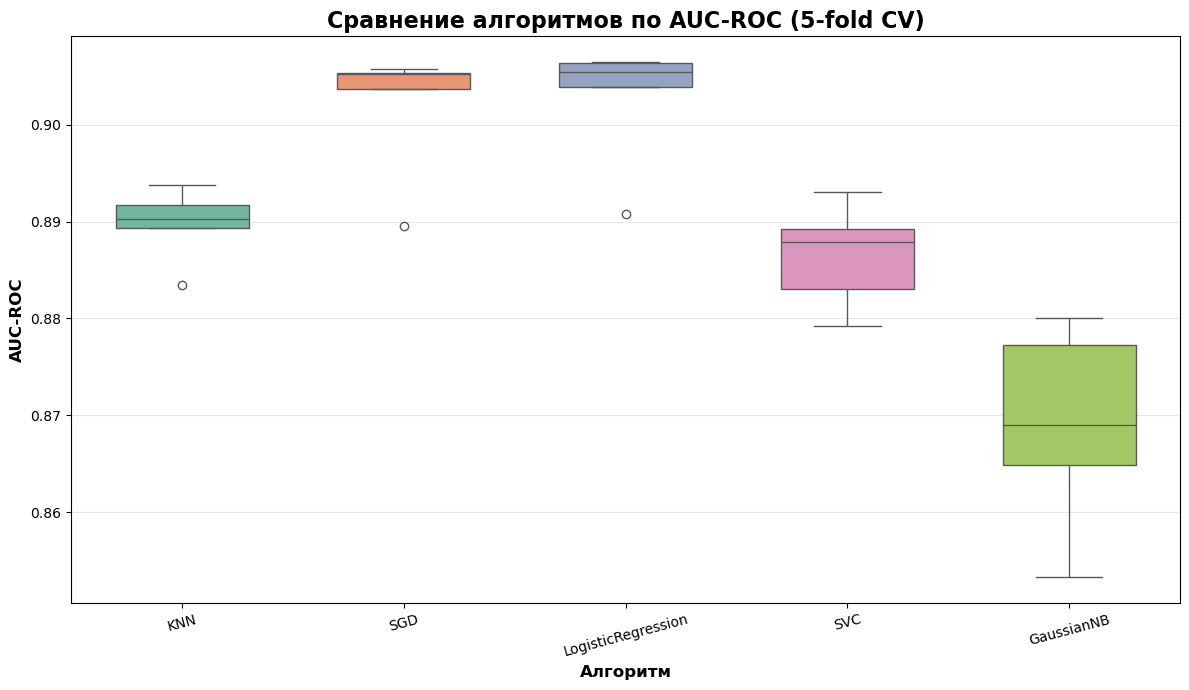

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

best_models = {
    'KNN': KNeighborsClassifier(n_neighbors=45, metric='manhattan'),
    'SGD': SGDClassifier(alpha=0.001, loss='log_loss', penalty='elasticnet'),
    'LogisticRegression': LogisticRegression(C=0.1, penalty='l2', solver='lbfgs'),
    'SVC': SVC(C=0.001, kernel='rbf'),
    'GaussianNB': GaussianNB(var_smoothing=0.0001)
}

# сбор результатов с лучших моделей
cv_results = {}
for name, model in best_models.items():
    scores = cross_val_score(model, X_train_final, ytrain, cv=cv, scoring='roc_auc')
    cv_results[name] = scores
    print(f"{name}: mean={scores.mean():.4f}, std={scores.std():.4f}")
df_scores = pd.DataFrame(cv_results)
df_melted = df_scores.melt(var_name='Algorithm', value_name='AUC-ROC')

# построение boxplot
plt.figure(figsize=(12, 7))
sns.boxplot(x='Algorithm', hue='Algorithm', y='AUC-ROC', data=df_melted, palette='Set2', width=0.6, legend=False)

plt.title('Сравнение алгоритмов по AUC-ROC (5-fold CV)', fontsize=16, fontweight='bold')
plt.xlabel('Алгоритм', fontsize=12, fontweight='bold')
plt.ylabel('AUC-ROC', fontsize=12, fontweight='bold')
plt.xticks(rotation=15)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

####12.2. Сделайте общие итоговые выводы о классификаторах с точки зрения их работы с признаками и сложности самой модели (какие гиперпараметры есть у модели, сильно ли изменение значения гиперпараметра влияет на качество модели).

**Ваш ответ здесь:**

**KNN (k-Nearest Neighbors)**

Особенности работы с признаками:
- Очень чувствителен к масштабу! Без стандартизации признаки с большими значениями (fnlwgt, capital-gain) доминируют
- Не работает напрямую с категориальными признаками, требует кодирования
- Высокая интерпретируемость

Гиперпараметры и их влияние:
- n_neighbors (главный): 
  - Маленькие значения (3-5) - переобучение, высокая вариативность
  - Большие значения (20+) - сглаживание, но может потерять важные паттерны
  - Оптимум обычно 5-15, сильно влияет на качество
- metric (евклидова/манхэттенская) - Влияет умеренно, но выбор метрики может дать прирост 1-3%
- **Вывод**: гиперпараметры **очень сильно влияют** на качество

Сложность модели:
- Время обучения: мгновенно, ленивое обучение
- Время предсказания: зависит от размера данных
- Сложность: низкая, нет внутренней оптимизации

**SGDClassifier (Stochastic Gradient Descent)**

Особенности работы с признаками:
- Очень чувствителен к масштабу, необходима стандартизация
- Требует кодирования категориальных признаков
- Эффективен в работе с большими данными, обучается по частям
- Устойчивость к выбросам зависит от функции потерь (modified_huber устойчивее)

Гиперпараметры и их влияние:
- loss (функция потерь):
  - log_loss - вероятности, хорош для вероятностных предсказаний
  - hinge - классический SVM, устойчив к выбросам
  - modified_huber - компромиссный вариант
  - Влияние: умеренное (разница 1-2%)
- penalty (регуляризация):
  - l2 - стандартный выбор, хорошо работает
  - l1 - разреженные веса, важность признаков
  - elasticnet - комбинация l1/l2
  - Влияние: существенное при большом числе признаков
- alpha (сила регуляризации):
  - Маленькое - переобучение
  - Большое - недообучение
  - Влияние: **очень сильное**, критично для качества
- **Вывод**: гиперпараметры **сильно влияют** на качество

Сложность модели:
- Время обучения: быстрое, итеративное
- Время предсказания: мгновенное, линейная модель
- Сложность: средняя, требует настройки скорости обучения

**Logistic Regression**

Особенности работы с признаками:
- Чувствительна к масштабу, рекомендуется стандартизация
- Требует кодирования категориальных признаков
- Очень высокая интерпретируемость (коэффициенты показывают важность признаков)
- Линейность: строит линейную границу, неэффективна при сложных зависимостях

Гиперпараметры и их влияние:
- C (обратная сила регуляризации):
  - Маленькое C (0.01) - слабая регуляризация, может недообучаться
  - Большое C (100) - сильная регуляризация, может переобучаться
  - Влияние: **очень сильное**, критично для баланса смещение-дисперсия
- penalty (тип регуляризации):
  - l2 - стандарт, хорошо работает
  - l1 - создает разреженные веса (отбор признаков)
  - Влияние: умеренное, больше влияет на интерпретацию
- solver (метод оптимизации):
  - liblinear - для небольших данных
  - saga - для больших данных, поддерживает l1
  - lbfgs - хороший выбор по умолчанию
  - Влияние: слабое (в основном на скорость)
- **Вывод**: гиперпараметры **сильно влияют** на качество

Сложность модели:
- Время обучения - быстрое
- Время предсказания - мгновенное
- Сложность - низкая, хорошо интерпретируемая


**SVC (Support Vector Classifier)**

Особенности работы с признаками:
- Критически чувствителен к масштабу, стандартизация обязательна!
- Требует кодирования категориальных признаков
- Работа с нелинейностями: RBF ядро отлично захватывает сложные зависимости
- Чувствителен к выбросам, но параметр C регулирует влияние

Гиперпараметры и их влияние:
- C (штраф за ошибки):
  - Маленькое C - мягкий margin, может недообучаться
  - Большое C - жесткий margin, может переобучаться
  - Влияние: **очень сильное**, определяет сложность модели
- kernel (ядро):
  - rbf - универсальный выбор для нелинейных данных
  - linear - для линейно разделимых данных
  - poly - для полиномиальных зависимостей
  - Влияние: **критическое**, определяет класс функций
- gamma (для RBF ядра):
  - Маленькое - далекое влияние точек, сглаживание
  - Большое - близкое влияние, может переобучаться
  - Влияние: **очень сильное**, особенно в паре с C
- **Вывод**: гиперпараметры **критически сильно влияют** на качество

Сложность модели:
- Время обучения: медленное, особенно с RBF ядром
- Время предсказания: зависит от числа опорных векторов
- Сложность: высокая, сложно интерпретировать

**Gaussian Naive Bayes**

Особенности работы с признаками:
- Не чувствителен к масштабу (работает с распределениями)
- Требует, чтобы признаки были нормально распределены
- Требует кодирования категориальных признаков
- Предполагает независимость признаков (редко выполняется)

Гиперпараметры и их влияние:
- var_smoothing (сглаживание дисперсии):
  - Маленькое (1e-9) → меньше сглаживания, может быть нестабильно
  - Большое (1e-4) → больше сглаживания, стабильнее
  - Влияние: умеренное, на качество влияет слабо (0.1-0.5%)
- **Вывод**: гиперпараметры **слабо влияют** на качество

Сложность модели:
- Время обучения: мгновенное, один проход
- Время предсказания: мгновенное
- Сложность: очень низкая, простой вероятностный подход

**Итоговые выводы:**

- **Для интерпретируемости**: Logistic Regression (коэффициенты показывают важность признаков)
- **Для сложных нелинейных зависимостей**: SVC с RBF ядром (лучшее качество, но медленно)
- **Для больших данных**: SGDClassifier (быстрое обучение)
- **Для быстрых предсказаний**: GaussianNB (мгновенно)
- **Для маленьких данных**: KNN (простота, хорошая интерпретация)
- **Обязательная стандартизация** для всех алгоритмов, кроме GaussianNB
- **Категориальные признаки** требуют кодирования для всех алгоритмов
- **Наиболее стабильный**: Logistic Regression (хороший баланс качества/интерпретации/скорости)